# StateGraph와 노드·엣지

**이 노트북에서 할 일**

1. 상태 칸 세 개를 적고 노드로 쓸 함수 두 개를 만듭니다.
2. 두 함수를 손으로 이어 부른 뒤 같은 일을 그래프로 옮깁니다.
3. 질문 하나만 바꿔 다시 실행하고 두 실행을 기록으로 견줍니다.
4. 노드를 등록한 차례만 바꿔 실행 순서가 달라지는지 봅니다.

**준비물** — 이 절은 OpenAI API 키를 쓰지 않습니다.
모델 요청이 0번이라 드는 비용이 없습니다.
읽어 오는 자료 파일도 없고 새로 쓰는 파일도 없습니다.
실행 시간은 1분 안팎이고 첫 셀의 설치가 가장 오래 걸립니다.

**기준 버전** — 첫 셀에서 LangGraph 1.2.11을 설치합니다.
실습 폴더 잠금 파일은 LangChain 1.4.0도 함께 고정하지만 이 절은 부르지 않습니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~6절과 11~14절을 읽습니다.
상태 칸을 적고 노드 함수를 만든 뒤 그래프로 옮기는 자리입니다.
7~10절은 같은 두 함수를 손으로 이어 부르는 자리이고 15~17절은 값 바꿔 보기입니다.
18~21절과 22~24절은 함께 실행하고 실습 시간에 다시 읽습니다.

실습 폴더 `labs/part4/ch13-langgraph-basics`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

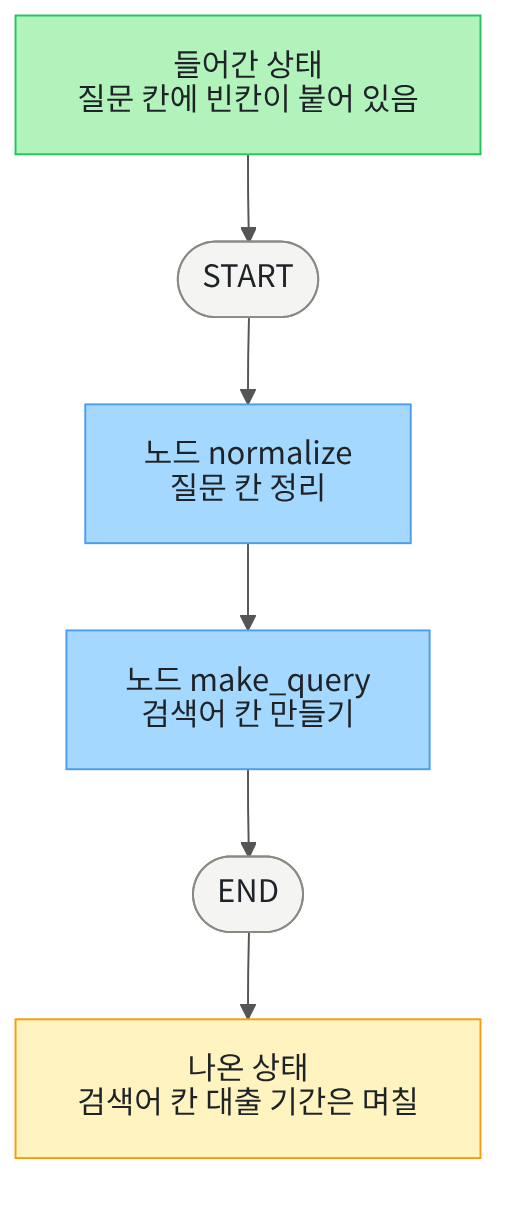

맨 위 초록 상자가 그래프에 넣은 상태입니다.
가운데 파란 상자 두 개가 우리가 만든 노드이고 위에서 아래로 읽습니다.
회색 둥근 상자 두 개는 LangGraph가 두는 가상 지점입니다.
맨 아래 노란 상자는 이 노트북의 출력으로 확인한 결과입니다.

## 1. 준비

첫 셀은 패키지 하나를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11"
from importlib.metadata import version

print("langgraph:", version("langgraph"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11


**결과 읽기** — 설치가 끝나면 `langgraph: 1.2.11`이 보입니다.
이 노트북의 출력은 2026-09-19에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름 네 개를 불러옵니다.

In [2]:
# 상태 형식과 그래프 만들기에 쓸 이름 네 개를 불러옵니다
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

print("불러온 이름:", "TypedDict", "StateGraph", "START", "END")

불러온 이름: TypedDict StateGraph START END


**결과 읽기** — 출력 줄은 `불러온 이름: TypedDict StateGraph START END` 하나입니다.
형식 `TypedDict`는 어떤 칸에 어떤 값이 들어가는지 적어 두는 딕셔너리 형식입니다.
설계 객체 `StateGraph`는 노드와 엣지를 모아 그래프를 만드는 이름입니다.
이름 `START`와 `END`는 LangGraph가 두는 가상 시작점과 가상 끝점입니다.

## 2. 이 절에서 쓸 질문 정하기

질문 두 개를 미리 정해 둡니다.
앞뒤에 빈칸을 일부러 넣어 첫 노드가 할 일을 만듭니다.

In [3]:
# 이 절에서 쓸 질문 두 개를 정합니다(앞뒤에 빈칸을 일부러 넣었습니다)
first_question = "  대출 기간은 며칠인가요?  "
second_question = "  주말 운영 시간은 언제인가요?  "
print("첫 질문:", first_question)
print("첫 질문의 글자 수:", len(first_question))
print("바꿔 볼 질문:", second_question)

첫 질문:   대출 기간은 며칠인가요?  
첫 질문의 글자 수: 17
바꿔 볼 질문:   주말 운영 시간은 언제인가요?  


**결과 읽기** — 출력 줄 `첫 질문의 글자 수: 17`에서 앞뒤 빈칸 네 개가 함께 세어졌습니다.
질문 자체는 열세 글자이고 나머지 네 글자가 빈칸입니다.
빈칸은 화면에서 잘 보이지 않으므로 글자 수로 확인합니다.

## 3. 상태 칸 적기

상태는 그래프가 도는 동안 노드들이 함께 읽고 고치는 값입니다.
공용 게시판에 칸이 셋 있고 사람마다 맡은 칸에만 적는 모습과 같습니다.
다음 셀은 그 칸 세 개의 이름과 값 갈래를 적습니다.
Ch 2 06절에서 배운 `class` 문을 Part 2·3에서는 쓰지 않았습니다.
여기서는 라이브러리가 상태 형식을 요구해 필드만 적은 형식 하나를 만듭니다.

In [4]:
# 그래프가 도는 동안 노드들이 함께 읽고 고칠 칸 세 개를 적습니다
class FlowState(TypedDict):
    question: str
    query: str
    trace: list[str]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸 이름 뒤 `: str`은 그 칸에 문자열이 들어간다는 표시입니다.
표시 `list[str]`은 문자열을 담은 목록이라는 뜻입니다.
칸 `trace`에는 지나간 노드 이름을 차례로 담아 실행 흔적으로 씁니다.

다음 셀은 상태를 칸별로 출력하는 함수입니다.

In [5]:
# 상태의 칸 세 개를 라벨 줄 아래에 한 줄씩 출력합니다
def print_state(label, state):
    print(label)
    print("질문 칸 |", state["question"])
    print("검색어 칸 |", state["query"])
    print("실행 흔적 칸 |", state["trace"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
라벨 줄을 따로 출력하고 그 아래에 칸을 한 줄씩 적습니다.

## 4. 노드로 쓸 함수 두 개 만들기

노드는 상태를 받아 바꿀 칸만 딕셔너리로 내놓는 함수입니다.
먼저 질문 칸을 정리하는 함수를 만듭니다.

In [6]:
# 질문 칸의 앞뒤 빈칸을 없애고 이 노드가 지난 자취를 실행 흔적에 붙입니다
def normalize(state):
    clean_question = state["question"].strip()
    new_trace = state["trace"] + ["normalize"]
    return {"question": clean_question, "trace": new_trace}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
메서드 `strip()`은 글 앞뒤의 빈칸을 없앱니다.
실행 흔적 칸에는 기존 목록 뒤에 이름 하나를 붙여 새 목록을 만듭니다.
칸마다 합치는 규칙을 상태에 적어 두는 방법은 02절에서 배웁니다.

다음 셀은 그 함수를 그래프 없이 직접 불러 봅니다.

In [7]:
# 노드 함수도 보통 함수입니다. 그래프 없이 직접 불러 봅니다
hand_state = {"question": first_question, "query": "", "trace": []}
first_update = normalize(hand_state)
print("normalize가 낸 갱신:", first_update)
print("갱신에 든 칸 수:", len(first_update))

normalize가 낸 갱신: {'question': '대출 기간은 며칠인가요?', 'trace': ['normalize']}
갱신에 든 칸 수: 2


**결과 읽기** — 출력 줄에 `{'question': '대출 기간은 며칠인가요?', 'trace': ['normalize']}`가 보입니다.
앞뒤 빈칸이 사라졌고 실행 흔적에 이름 하나가 담겼습니다.
출력 줄 `갱신에 든 칸 수: 2`에서 검색어 칸이 빠진 것을 확인합니다.
노드는 자기가 바꾸는 칸만 내놓습니다.

다음 셀은 검색어 칸을 만드는 함수입니다.

In [8]:
# 물음표와 맺음말을 지워 검색어 칸에 넣을 말을 만듭니다
def make_query(state):
    without_mark = state["question"].replace("?", "")
    plain = without_mark.replace("인가요", "")
    new_trace = state["trace"] + ["make_query"]
    return {"query": plain.strip(), "trace": new_trace}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
메서드 `replace()`는 글에서 찾은 말을 다른 말로 바꿉니다.
여기서는 물음표와 맺음말 `인가요`를 빈 글로 바꿔 지웁니다.

다음 셀은 앞 갱신을 상태에 합친 뒤 이 함수를 불러 봅니다.

In [9]:
# 앞 갱신을 상태에 합친 뒤 두 번째 노드 함수를 불러 봅니다
hand_state.update(first_update)
second_update = make_query(hand_state)
print("make_query가 낸 갱신:", second_update)
print("갱신에 든 칸 수:", len(second_update))

make_query가 낸 갱신: {'query': '대출 기간은 며칠', 'trace': ['normalize', 'make_query']}
갱신에 든 칸 수: 2


**결과 읽기** — 출력 줄에 `{'query': '대출 기간은 며칠', 'trace': ['normalize', 'make_query']}`가 보입니다.
검색어 칸에 물음표와 맺음말이 빠진 말이 담겼습니다.
실행 흔적에는 이름 두 개가 차례로 쌓였습니다.

## 5. 손으로 이어 부른 결과 보기

메서드 `update()`는 딕셔너리에 다른 딕셔너리의 칸을 덮어 씁니다.
갱신을 상태에 합치는 일을 손으로 한 셈입니다.

In [10]:
# 두 번째 갱신까지 합쳐 손으로 이어 부른 결과를 봅니다
hand_state.update(second_update)
print_state("손으로 이어 부른 결과", hand_state)

손으로 이어 부른 결과
질문 칸 | 대출 기간은 며칠인가요?
검색어 칸 | 대출 기간은 며칠
실행 흔적 칸 | ['normalize', 'make_query']


**결과 읽기** — 라벨 줄 `손으로 이어 부른 결과` 아래 세 줄이 나옵니다.
줄 `검색어 칸 | 대출 기간은 며칠`이 두 함수를 지난 결과입니다.
줄 `실행 흔적 칸 | ['normalize', 'make_query']`에 지나온 차례가 남았습니다.
여기까지는 그래프를 쓰지 않았고 부르는 차례를 코드 줄이 정했습니다.

## 6. 같은 일을 그래프로 옮기기

이제 같은 두 함수를 그래프에 등록합니다.
등록은 함수를 부르는 것이 아니라 이름과 함수를 짝지어 적어 두는 일입니다.

In [11]:
# 노드 두 개를 그래프에서 쓸 이름과 함께 설계 객체에 등록합니다
builder = StateGraph(FlowState)
builder.add_node("normalize", normalize)
builder.add_node("make_query", make_query)
print("등록한 노드 수:", len(builder.nodes))
print("등록한 노드 이름:")
for node_name in builder.nodes:
    print(node_name)

등록한 노드 수: 2
등록한 노드 이름:
normalize
make_query


**결과 읽기** — 출력 줄 `등록한 노드 수: 2`가 보입니다.
라벨 줄 `등록한 노드 이름:` 아래 두 줄은 `normalize`와 `make_query`입니다.
등록만 했을 뿐 아직 함수 본문은 실행되지 않았습니다.

다음 셀은 실행 순서를 엣지로 적습니다.

In [12]:
# START부터 END까지 실행 순서를 엣지 세 개로 적습니다
builder.add_edge(START, "normalize")
builder.add_edge("normalize", "make_query")
builder.add_edge("make_query", END)
edge_order = ["START", "normalize", "make_query", "END"]
print("엣지로 적은 실행 순서:", edge_order)

엣지로 적은 실행 순서: ['START', 'normalize', 'make_query', 'END']


**결과 읽기** — 출력 줄 `엣지로 적은 실행 순서: ['START', 'normalize', 'make_query', 'END']`가 보입니다.
엣지 하나가 「이 노드 다음에는 저 노드」라는 이동 한 칸입니다.
가상 시작점에서 첫 노드로, 마지막 노드에서 가상 끝점으로 가는 엣지도 적습니다.

다음 셀은 적어 둔 구조를 실행할 수 있는 그래프로 만듭니다.

In [13]:
# 선언한 구조를 확인해 실행할 수 있는 그래프로 만듭니다
graph = builder.compile()
print("설계 객체의 종류:", type(builder))
print("컴파일 결과의 종류:", type(graph))

설계 객체의 종류: <class 'langgraph.graph.state.StateGraph'>
컴파일 결과의 종류: <class 'langgraph.graph.state.CompiledStateGraph'>


**결과 읽기** — 출력 줄 두 개의 종류 이름이 서로 다릅니다.
설계 객체는 `StateGraph`이고 컴파일 결과는 `CompiledStateGraph`입니다.
컴파일하기 전 객체는 적어 둔 설계도이고 컴파일 결과가 실행하는 객체입니다.

## 7. 실행 1 — 첫 질문

실행 전에 예상해 봅니다.
검색어 칸에는 손으로 이어 부른 결과와 같은 말이 담길 것입니다.

In [14]:
# 컴파일한 그래프에 첫 상태를 넣어 실행합니다
first_state = {"question": first_question, "query": "", "trace": []}
first_result = graph.invoke(first_state)
print_state("그래프 실행 1 결과", first_result)

그래프 실행 1 결과
질문 칸 | 대출 기간은 며칠인가요?
검색어 칸 | 대출 기간은 며칠
실행 흔적 칸 | ['normalize', 'make_query']


**결과 읽기** — 라벨 줄 `그래프 실행 1 결과` 아래 세 줄이 나옵니다.
줄 `검색어 칸 | 대출 기간은 며칠`과 줄 `실행 흔적 칸 | ['normalize', 'make_query']`가 보입니다.
빈 글로 넣은 검색어 칸이 둘째 노드에서 채워졌습니다.

다음 셀은 손으로 이어 부른 결과와 칸별로 견줍니다.

In [15]:
# 손으로 이어 부른 결과와 그래프가 낸 결과를 칸별로 견줍니다
print("검색어 칸이 같은가:", hand_state["query"] == first_result["query"])
print("실행 흔적이 같은가:", hand_state["trace"] == first_result["trace"])
assert first_result["trace"] == ["normalize", "make_query"]

검색어 칸이 같은가: True
실행 흔적이 같은가: True


**결과 읽기** — 출력 줄 `검색어 칸이 같은가: True`와 `실행 흔적이 같은가: True`가 보입니다.
같은 두 함수를 썼으니 결과가 같습니다.
달라진 것은 실행 순서를 어디에 적었는가입니다.
손으로 부를 때는 코드 줄의 차례가, 그래프에서는 엣지가 순서를 정했습니다.

## 8. 값 바꿔 보기 — 질문 하나만 바꾸기

바꿀 값은 질문 하나입니다.
그래프와 처음 칸 값은 그대로 둡니다.
실행 전에 예상해 봅니다. 검색어 칸은 달라지고 실행 흔적은 같을 것입니다.

In [16]:
# 질문만 바꾸고 그래프와 처음 칸 값은 그대로 두어 다시 실행합니다
second_state = {"question": second_question, "query": "", "trace": []}
second_result = graph.invoke(second_state)
print_state("그래프 실행 2 결과", second_result)

그래프 실행 2 결과
질문 칸 | 주말 운영 시간은 언제인가요?
검색어 칸 | 주말 운영 시간은 언제
실행 흔적 칸 | ['normalize', 'make_query']


**결과 읽기** — 줄 `검색어 칸 | 주말 운영 시간은 언제`로 값이 달라졌습니다.
줄 `실행 흔적 칸 | ['normalize', 'make_query']`는 실행 1과 같습니다.
엣지로 고정한 순서라 질문 내용이 순서를 바꾸지 못했습니다.

## 9. 두 실행을 기록 한 줄씩으로

실행 한 번을 기록 한 줄로 만들어 담아 둡니다.
Ch 9~12에서 쓴 기록 한 줄과 같은 모양입니다.

In [17]:
# 실행 한 번을 기록 한 줄로 만듭니다
def run_row(run_name, state):
    row = {"실행": run_name}
    row["검색어 칸"] = state["query"]
    row["실행 흔적"] = state["trace"]
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 두 실행의 기록을 목록에 담습니다.

In [18]:
# 두 실행의 기록을 목록에 담습니다
run_rows = []
run_rows.append(run_row("실행 1", first_result))
run_rows.append(run_row("실행 2", second_result))
print("담은 기록 줄 수:", len(run_rows))

담은 기록 줄 수: 2


**결과 읽기** — 출력 줄 `담은 기록 줄 수: 2`가 보입니다.

다음 셀은 담은 줄을 표로 출력합니다.

In [19]:
# 실행·검색어 칸·실행 흔적을 라벨 줄 아래에 차례로 출력합니다
print("실행 | 검색어 칸 | 실행 흔적")
for row in run_rows:
    print(row["실행"], "|", row["검색어 칸"], "|", row["실행 흔적"])

실행 | 검색어 칸 | 실행 흔적
실행 1 | 대출 기간은 며칠 | ['normalize', 'make_query']
실행 2 | 주말 운영 시간은 언제 | ['normalize', 'make_query']


**결과 읽기** — 라벨 줄 아래 두 줄이 나옵니다.
줄 `실행 1 | 대출 기간은 며칠 | ['normalize', 'make_query']`가 첫 실행입니다.
줄 `실행 2 | 주말 운영 시간은 언제 | ['normalize', 'make_query']`가 질문만 바꾼 실행입니다.
검색어 칸만 달라지고 실행 흔적 칸은 같습니다.

## 10. 그래프가 그린 구조 보기

그래프는 자기 구조를 문자열로 그려 줍니다.
우리가 적은 엣지가 그대로 있는지 확인합니다.

In [20]:
# 컴파일한 그래프가 스스로 그린 구조 문자열을 받아 옵니다
mermaid_text = graph.get_graph().draw_mermaid()
print("그래프가 그린 구조:")
print(mermaid_text)

그래프가 그린 구조:
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	normalize(normalize)
	make_query(make_query)
	__end__([<p>__end__</p>]):::last
	__start__ --> normalize;
	normalize --> make_query;
	make_query --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



**결과 읽기** — 라벨 줄 `그래프가 그린 구조:` 아래에 여러 줄이 나옵니다.
줄 `normalize --> make_query;`가 우리가 적은 둘째 엣지입니다.
줄 `__start__ --> normalize;`와 `make_query --> __end__;`도 보입니다.
이 문자열은 LangGraph가 만든 것이라 색과 모양이 교재 도식과 다릅니다.

다음 셀은 그래프에 남은 노드 이름을 한 줄씩 봅니다.

In [21]:
# 그래프에 남은 노드 이름을 한 줄씩 출력해 우리가 적은 이름과 맞춰 봅니다
graph_nodes = graph.get_graph().nodes
print("그래프에 있는 노드 이름:")
for node_name in graph_nodes:
    print(node_name)

그래프에 있는 노드 이름:
__start__
normalize
make_query
__end__


**결과 읽기** — 라벨 줄 아래 네 줄이 나옵니다.
이름 `__start__`와 `__end__`는 라이브러리가 붙인 가상 지점 이름입니다.
가운데 두 줄이 우리가 등록한 `normalize`와 `make_query`입니다.

## 11. 값 바꿔 보기 — 등록 차례만 바꾸기

이번에 바꿀 값은 노드를 등록하는 차례 하나입니다.
엣지 세 개와 질문은 그대로 둡니다.
실행 전에 예상해 봅니다. 실행 흔적은 실행 1과 같을 것입니다.

In [22]:
# 노드를 등록하는 차례만 바꿔 설계 객체를 하나 더 만듭니다
swapped = StateGraph(FlowState)
swapped.add_node("make_query", make_query)
swapped.add_node("normalize", normalize)
print("등록한 차례:")
for node_name in swapped.nodes:
    print(node_name)

등록한 차례:
make_query
normalize


**결과 읽기** — 라벨 줄 `등록한 차례:` 아래 첫 줄이 `make_query`입니다.
실행 1에 쓴 그래프와 등록 차례가 뒤바뀌었습니다.

다음 셀은 엣지를 똑같이 적고 컴파일합니다.

In [23]:
# 엣지 세 개는 실행 1에 쓴 그래프와 똑같이 적고 컴파일합니다
swapped.add_edge(START, "normalize")
swapped.add_edge("normalize", "make_query")
swapped.add_edge("make_query", END)
swapped_graph = swapped.compile()
print("컴파일 결과의 종류:", type(swapped_graph))

컴파일 결과의 종류: <class 'langgraph.graph.state.CompiledStateGraph'>


**결과 읽기** — 출력 줄의 종류 이름이 `CompiledStateGraph`로 실행 1의 그래프와 같습니다.
엣지 세 개도 실행 1에 쓴 그래프와 글자까지 같습니다.

다음 셀은 같은 첫 질문으로 이 그래프를 실행합니다.

In [24]:
# 같은 첫 질문으로 등록 차례를 바꾼 그래프를 실행합니다
swapped_state = {"question": first_question, "query": "", "trace": []}
swapped_result = swapped_graph.invoke(swapped_state)
print_state("등록 차례를 바꾼 그래프 결과", swapped_result)
print("실행 1과 실행 흔적이 같은가:", swapped_result["trace"] == first_result["trace"])

등록 차례를 바꾼 그래프 결과
질문 칸 | 대출 기간은 며칠인가요?
검색어 칸 | 대출 기간은 며칠
실행 흔적 칸 | ['normalize', 'make_query']
실행 1과 실행 흔적이 같은가: True


**결과 읽기** — 줄 `실행 흔적 칸 | ['normalize', 'make_query']`가 보입니다.
출력 줄 `실행 1과 실행 흔적이 같은가: True`로 두 실행이 같음을 확인했습니다.
등록 차례를 바꿔도 실행 순서는 엣지가 정했습니다.
노드가 셋 이상이거나 갈래가 있는 그래프는 이번에 실행하지 않았습니다.

## 정리

1. 노드는 상태를 받아 바꿀 칸만 내놓는 보통 함수였습니다.
2. 같은 두 함수를 손으로 이어 부른 결과와 그래프 실행 1 결과가 같았습니다.
3. 질문을 바꾸거나 등록 차례를 바꿔도 실행 흔적은 `['normalize', 'make_query']`였습니다.

02절에서는 같은 칸에 갱신이 여러 번 모일 때 합치는 규칙을 상태에 적어 둡니다.
이 절에서 코드로 직접 이어 붙인 실행 흔적을 그 규칙으로 옮깁니다.